# 클러스터링 결과 비교: OPTICS vs GRU vs Transformer

## 목적
- 전통적인 좌표 기반 클러스터링 (OPTICS)과 딥러닝 임베딩 기반 클러스터링 품질 비교
- t-SNE / UMAP을 이용한 시각적 비교
- Silhouette Score 등 정량적 지표 비교

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import OPTICS
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import umap
from pathlib import Path
import yaml

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_palette('husl')

BASE_DIR = Path('c:/Users/Public/Documents/DIK/deTACTer')
VERSIONS = ['v5.5', 'v5.6', 'v5.7']

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 데이터 로드 및 임베딩 추출

In [5]:
# 각 버전별 데이터 로드
data_dict = {}

for version in VERSIONS:
    print(f"Loading {version}...")
    # 1. 원본 좌표 데이터 (OPTICS용)
    seq_path = BASE_DIR / 'data' / 'refined' / version / 'attack_sequences.csv'
    if not seq_path.exists():
        print(f"  Checking {version} data... Not found.")
        continue
        
    df = pd.read_csv(seq_path)
    
    # 시퀀스별 좌표 평탄화 (Flatten)
    sequences = []
    seq_ids = df['sequence_id'].unique()
    
    for seq_id in seq_ids:
        seq = df[df['sequence_id'] == seq_id].sort_values('seq_position')
        # (Start X, Start Y) 좌표만 사용 + Zero Padding for fixed length (if needed)
        # 여기서는 DTW 대신 간단히 좌표를 1열로 펼쳐서 비교 (또는 기존 tactical_clustering 결과 활용)
        coords = seq[['start_x', 'start_y']].values.flatten()
        sequences.append(coords)
    
    # 최대 길이로 패딩 (Coordinate approach)
    max_len = max(len(s) for s in sequences)
    X_coords = np.zeros((len(sequences), max_len))
    for i, s in enumerate(sequences):
        X_coords[i, :len(s)] = s
        
    # 2. 임베딩 로드 (GRU / Transformer)
    emb_dir = BASE_DIR / 'results' / 'embeddings' / version
    gru_emb_path = emb_dir / 'gru_embeddings.npy'
    trans_emb_path = emb_dir / 'transformer_embeddings.npy'
    
    gru_emb = np.load(gru_emb_path) if gru_emb_path.exists() else None
    trans_emb = np.load(trans_emb_path) if trans_emb_path.exists() else None
    
    data_dict[version] = {
        'ids': seq_ids,
        'coords': X_coords,
        'gru_emb': gru_emb,
        'trans_emb': trans_emb
    }
    
    print(f"  Coords: {X_coords.shape}")
    if gru_emb is not None: print(f"  GRU Emb: {gru_emb.shape}")
    if trans_emb is not None: print(f"  Trans Emb: {trans_emb.shape}")

Loading v5.5...
  Coords: (124, 46)
  GRU Emb: (124, 64)
  Trans Emb: (124, 128)
Loading v5.6...
  Coords: (151, 46)
  GRU Emb: (151, 64)
  Trans Emb: (151, 128)
Loading v5.7...
  Coords: (185, 46)
  GRU Emb: (185, 64)
  Trans Emb: (185, 64)


## 2. 클러스터링 수행 및 평가

In [6]:
def evaluate_clustering(X, min_samples=5, method_name=""):
    if X is None:
        return None
        
    # OPTICS Clustering
    optics = OPTICS(min_samples=min_samples, metric='euclidean', n_jobs=-1)
    labels = optics.fit_predict(X)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    
    # Metrics
    if n_clusters > 1:
        sil_score = silhouette_score(X, labels)
        ch_score = calinski_harabasz_score(X, labels)
    else:
        sil_score = -1
        ch_score = -1
        
    return {
        'Method': method_name,
        'Clusters': n_clusters,
        'Noise': n_noise,
        'Silhouette': sil_score,
        'Calinski-Harabasz': ch_score,
        'Labels': labels
    }

results = []
cluster_histories = {}

for version, data in data_dict.items():
    print(f"Evaluating {version}...")
    
    # 1. Coordinate Baseline
    res_coord = evaluate_clustering(data['coords'], method_name=f"{version} (Coords)")
    if res_coord: results.append(res_coord)
    
    # 2. GRU Embedding
    res_gru = evaluate_clustering(data['gru_emb'], method_name=f"{version} (GRU)")
    if res_gru: results.append(res_gru)
    
    # 3. Transformer Embedding
    res_trans = evaluate_clustering(data['trans_emb'], method_name=f"{version} (Trans)")
    if res_trans: results.append(res_trans)
    
    cluster_histories[version] = {
        'coords': res_coord,
        'gru': res_gru,
        'trans': res_trans
    }

results_df = pd.DataFrame(results)
display(results_df)

Evaluating v5.5...
Evaluating v5.6...
Evaluating v5.7...


,Method,Clusters,Noise,Silhouette,Calinski-Harabasz,Labels
0,v5.5 (Coords),1,0,-1.000000,-1.000000,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,v5.5 (GRU),8,67,-0.008682,12.192590,"[0, 6, 7, 7, -1, 2, -1, 7, -1, -1, 5, 0, 1, -1..."
2,v5.5 (Trans),6,75,-0.076719,5.619543,"[-1, -1, -1, -1, -1, 3, 5, -1, 0, -1, -1, 0, 2..."
3,v5.6 (Coords),6,113,-0.094194,6.678726,"[-1, 5, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1,..."
4,v5.6 (GRU),8,88,-0.056912,11.987028,"[0, 7, -1, -1, -1, -1, -1, 2, 1, 5, 2, 3, 4, -..."
5,v5.6 (Trans),9,68,0.018839,15.695956,"[-1, 3, 5, -1, -1, 5, -1, 2, -1, -1, 5, -1, -1..."
6,v5.7 (Coords),5,143,-0.040931,9.296005,"[-1, -1, 0, -1, -1, 4, -1, 3, -1, -1, -1, -1, ..."
7,v5.7 (GRU),7,111,-0.081022,18.462533,"[-1, -1, 1, -1, 5, 1, -1, -1, -1, 0, -1, -1, 4..."
8,v5.7 (Trans),12,88,-0.025146,12.719151,"[-1, -1, 4, -1, -1, 11, 7, -1, -1, -1, -1, -1,..."


## 3. 시각화 (UMAP)

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\u

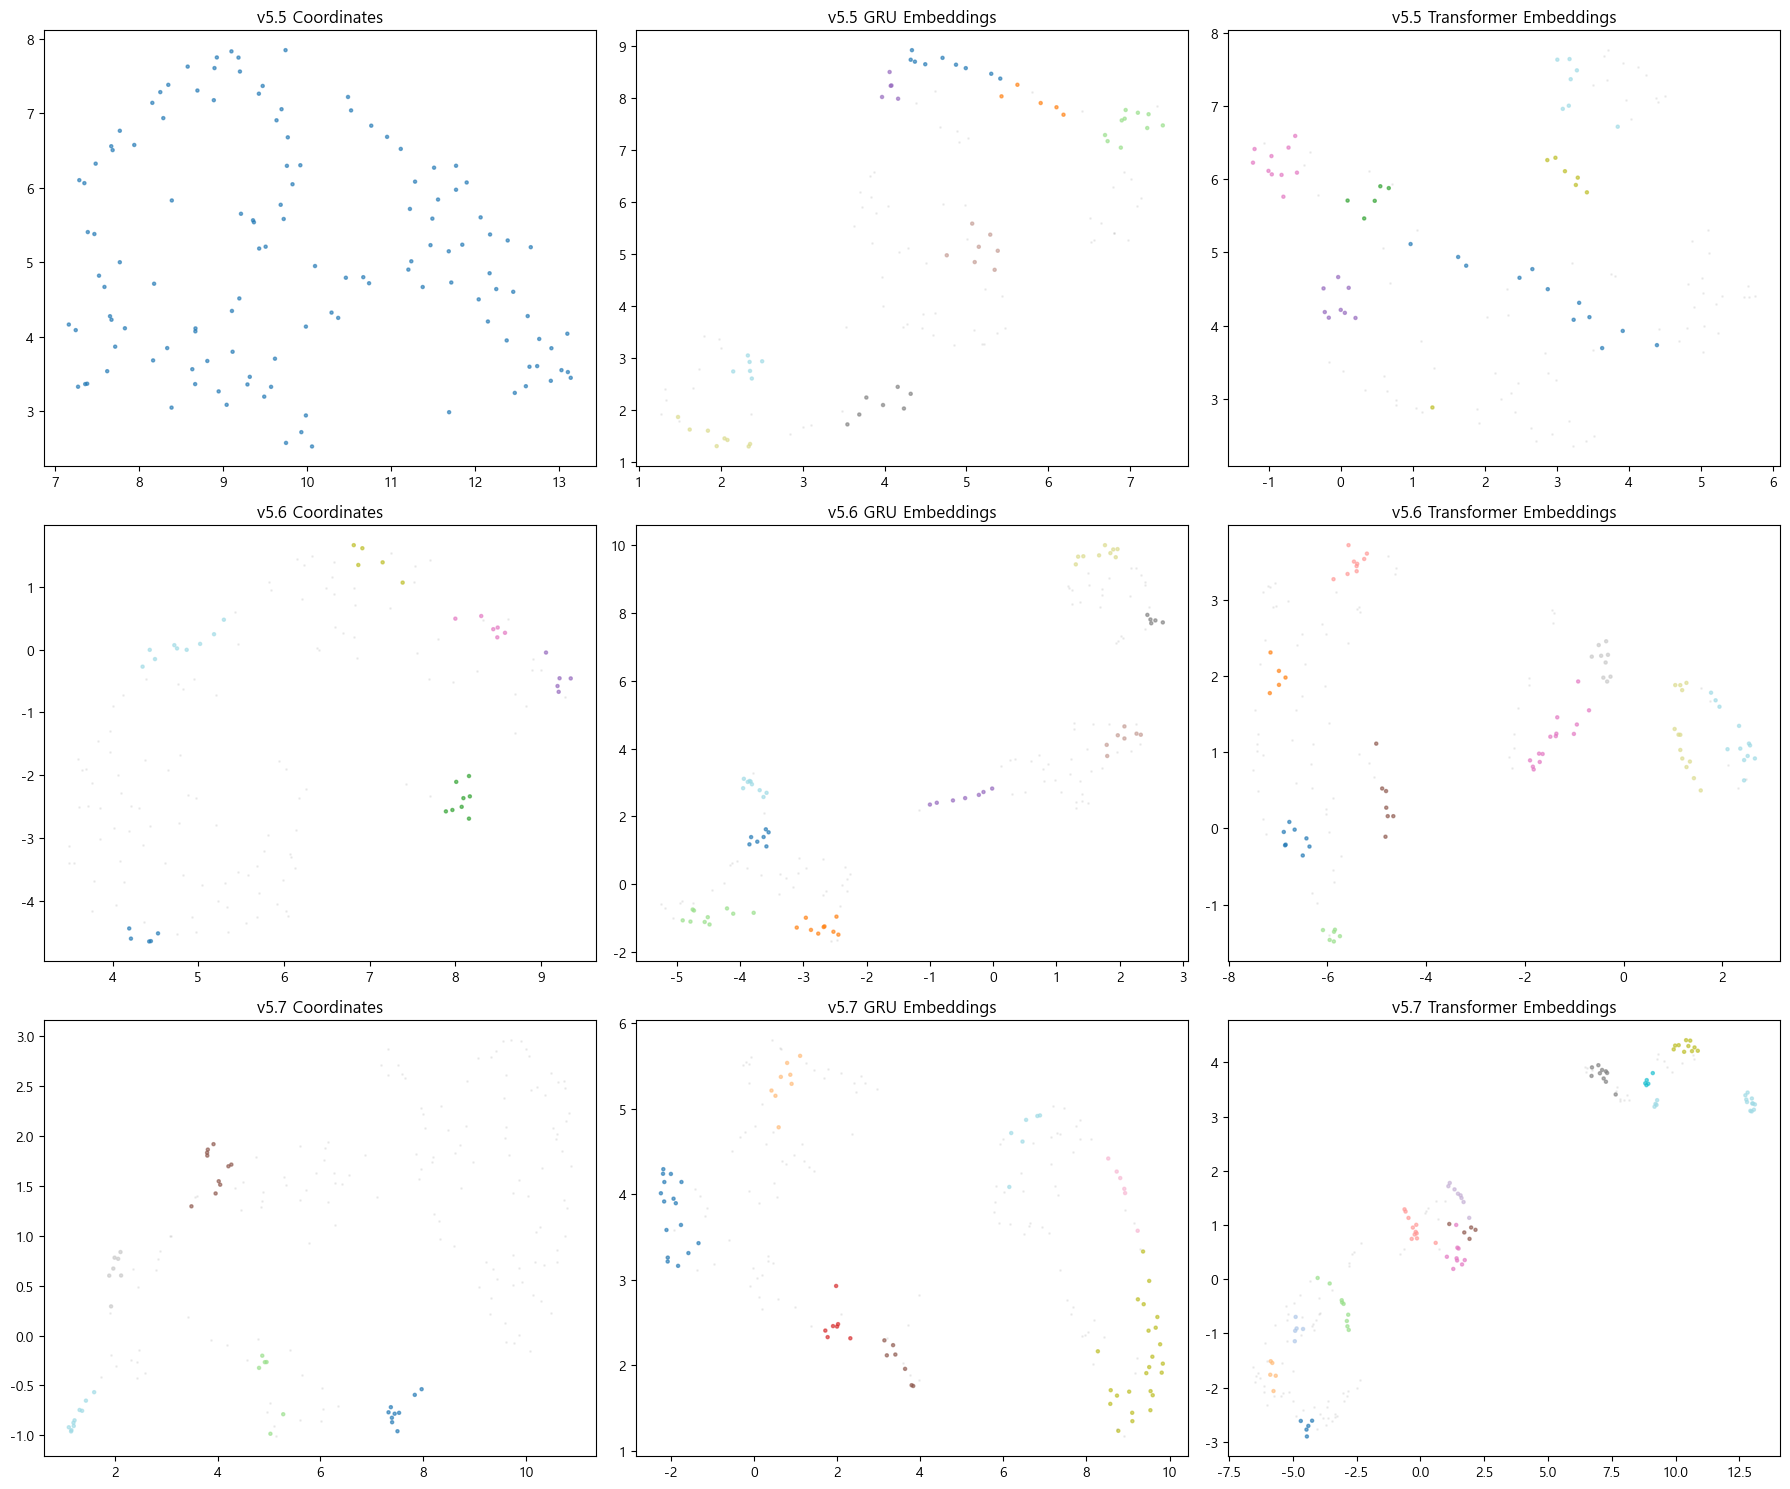

In [7]:
def plot_clusters(data, labels, title, ax):
    if data is None or labels is None:
        ax.text(0.5, 0.5, 'No Data', ha='center', va='center')
        return
        
    reducer = umap.UMAP(random_state=42)
    embedding = reducer.fit_transform(data)
    
    # 노이즈(-1)와 클러스터 분리
    mask = labels != -1
    
    # 클러스터
    ax.scatter(embedding[mask, 0], embedding[mask, 1], c=labels[mask], 
               cmap='tab20', s=5, alpha=0.6)
    # 노이즈
    ax.scatter(embedding[~mask, 0], embedding[~mask, 1], c='gray', 
               s=1, alpha=0.1, label='Noise')
               
    ax.set_title(title)

fig, axes = plt.subplots(len(VERSIONS), 3, figsize=(18, 5*len(VERSIONS)))

if len(VERSIONS) == 1: axes = axes.reshape(1, -1)

for i, version in enumerate(VERSIONS):
    if version not in data_dict:
        continue
        
    # Coords
    plot_clusters(data_dict[version]['coords'], 
                  cluster_histories[version]['coords']['Labels'] if cluster_histories[version]['coords'] else None,
                  f"{version} Coordinates", axes[i, 0])
    
    # GRU
    plot_clusters(data_dict[version]['gru_emb'], 
                  cluster_histories[version]['gru']['Labels'] if cluster_histories[version]['gru'] else None,
                  f"{version} GRU Embeddings", axes[i, 1])
                  
    # Transformer
    plot_clusters(data_dict[version]['trans_emb'], 
                  cluster_histories[version]['trans']['Labels'] if cluster_histories[version]['trans'] else None,
                  f"{version} Transformer Embeddings", axes[i, 2])

plt.tight_layout()
plt.savefig(BASE_DIR / 'results' / 'clustering_comparison.png', dpi=150)
plt.show()

## 4. 결론
1. **Coordinate vs Embedding**: 임베딩 방식이 시퀀스의 문맥을 포착하여 노이즈를 줄이고 클러스터 응집도를 높이는지 확인
2. **GRU vs Transformer**: GRU와 Transformer 임베딩 중 어느 것이 더 명확한 클러스터링 결과를 보이는지 확인
3. **Silhouette Score 비교**: 높을수록 좋은 클러스터링